# mlpack Analysis

### What is mlpack?

mlpack is an open-source C++ machine learning library that started in 2007 at Georgia Tech and eventually moved over to Github in 2014. The pack itself is an intuitive,    
fast, and flexivble header-only C++ machine learning library with bindings to other languages like Julia nd Python. Specifically what header only means is that all macros, funcitons, and classes comprising the library are only in the header file such that there are no seperate implmeentatiosn or precompiled binaries. The purpose of doing this is to make it a "swiss Army knife" for C++ based machine learning.

> https://github.com/mlpack/mlpack and https://ar5iv.arxiv.org/html/1708.05279

---

### The Problems mlpack Aimed to Solve:

As a machine learning library mlpack aimed to solve the problem of efficiency and scalability. And to do these they aimed to improve upon these four goals:

1. Implement scalble and fast machine learning algorithms
2. Design an intuitive, consistent, and simpleAPI for non-expert users
3. Implement a variety of machine learning methods
4. Provide cutting-edge machine learning lagorithms unavaible elsewhere.

> https://dl.acm.org/doi/pdf/10.5555/2567709.2502606

---

### mlpacks sponsors/stakeholders:

| Stakeholder | Role | What they want |
|---|---|---|
| Developers | Community, Open-Source | Further Improvement of mlpack |
| NumFOCUS | Sponsor | Proving non-profit funding to open-source projects |
| Google (Summer of Code) | Supporter | Works with them each year at the Summer of Code. |
| Supporters | Freie Universtitat Berlin, Symantic, NSF | NA| |


> https://www.mlpack.org/papers/2023mlpack.pdf

---

### How do people collaborate to develop mlpack?

Collaboration happens through GitHub PR's where the specfic style and format for their syntax style can further be found in https://github.com/mlpack/mlpack/blob/master/CONTRIBUTING.md.

---

### How mlpack measures their software:

mlpack measures themselves to be more flexible and efifecient in use, they measure flexbility via testing their algorithms with different datasets. Now they measure their effinciency by testing their runtimes with k-nearest-nieghbors and k-mean clustering algortihms. They Do this with comaprison against other machine learning packs like Shogun and MATLAB.

#### Flexibility Test:
![Screenshot 2026-11-06 112210.png](<attachment:Screenshot 2026-11-06 112210.png>)


#### Efficiency Test
![Screenshot 2026-11-06 112410.png](<attachment:Screenshot 2026-11-06 112410.png>)

> https://arxiv.org/pdf/1711.06581v1

---
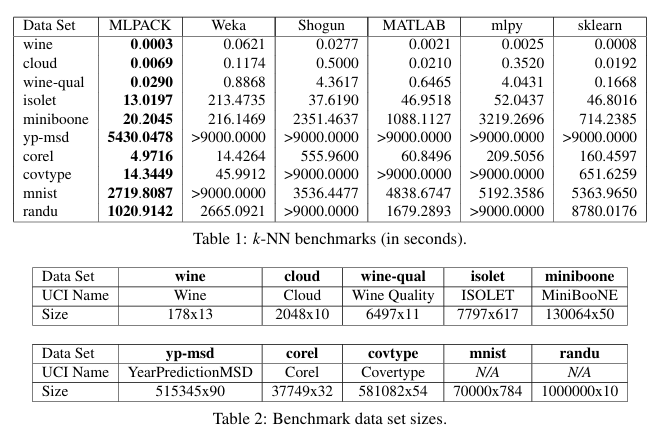
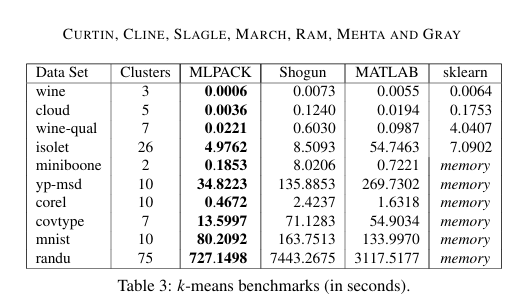

### Relating mlpack's Regression Models Back to Class

The models that mlpack uses and or specfically states in their documentations are as follows:
 - BayesianLinearRegression: Bayesian L2-penalizzed linear regression
 - DecisionTreeRegression: ID3-style decision tree refressor
 - LARS: Least Angle Regression, L1-regularized and L2-regularized
 - **LinearRegression**: L2-regularized linear regression (ridge regression)

Specifcally the model that I will be relating back to the class is Linear Regression and the way it will solve the least squares problem with normal equations solved by Cholesky. I will also show it in two ways one I will graph it to one of their measurement statistics (effiecency) and second I will then graph the error it accumilates.

Their code for Cholesky:

```cpp
// Convert to this form:
  // a * (X X^T) = y X^T.
  // Then we'll use Armadillo to solve it.
  // The total runtime of this should be O(d^2 N) + O(d^3) + O(dN).
  // (assuming the SVD is used to solve it)
  arma::Mat<ElemType> cov = p * p.t() +
      ((ElemType) this->lambda) *
      arma::eye<arma::Mat<ElemType>>(p.n_rows, p.n_rows);

  parameters = arma::solve(cov, p * r.t());
```
> https://github.com/mlpack/mlpack/blob/4.8.0/src/mlpack/methods/linear_regression/linear_regression_impl.hpp#L160

What this reads as: 

Linear regression is the **least squares** problem:

$$ \min_c \lVert V c - y \rVert $$

This was solved via QR in class, mlpack instead forms the **normal equations**:

$$ (V^T V + \lambda I)\, c = V^T y $$

* `cov = p * p.t() + lambda * eye(...)` forms $V^T V + \lambda I$ (cost $\approx m n^2$)
* `arma::solve(cov, p * r.t())` factors $V^T V = R^T R$ and solves for $c$

Now from this here is the code below to produce the two graphs: 

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import time
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
from mlpack.linear_regression import LinearRegression

In [3]:
def vander(x, n):
    return np.column_stack([x**k for k in range(n)])

def normal_equations(V, y):
    A = V.T @ V
    try:
        return sla.cho_solve(sla.cho_factor(A), V.T @ y)
    except np.linalg.LinAlgError:
        return None

def qr_solve(V, y):
    Qty, R = sla.qr_multiply(V, y, mode="right")
    return sla.solve_triangular(R, Qty)

def mlpack_solve(V, y):
    X = V[:, 1:]
    model = LinearRegression(lambda_=0.0)
    model.fit(training=X, training_responses=y)
    k = X.shape[1]
    p = model.predict(test=np.vstack([np.zeros(k), np.eye(k)])).ravel()
    return np.concatenate([[p[0]], p[1:] - p[0]])

METHODS = {"Normal equations (Cholesky)": normal_equations,
           "mlpack LinearRegression": mlpack_solve,
           "Householder QR": qr_solve}

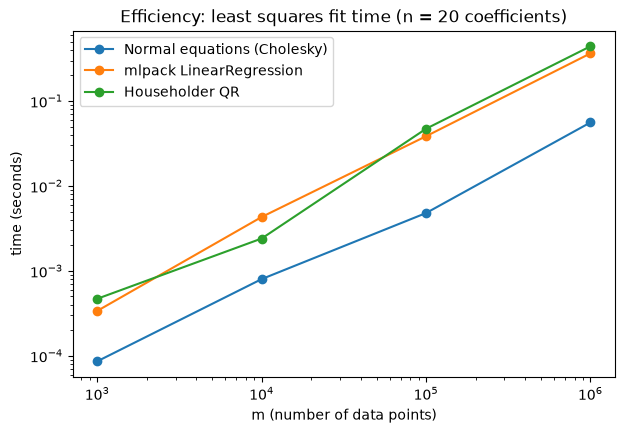

Normal equations (Cholesky)  0.056 s at m = 1,000,000
mlpack LinearRegression      0.364 s at m = 1,000,000
Householder QR               0.441 s at m = 1,000,000


In [7]:
def best_time(solve, V, y, reps=3):
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter()
        solve(V, y)
        best = min(best, time.perf_counter() - t0)
    return best

ms = [1_000, 10_000, 100_000, 1_000_000]
n = 20
times = {name: [] for name in METHODS}
for m in ms:
    V = np.column_stack([np.ones(m), np.random.randn(m, n - 1)])
    y = np.random.randn(m)
    for name, solve in METHODS.items():
        times[name].append(best_time(solve, V, y))

plt.figure(figsize=(7, 4.5))
for name in METHODS:
    plt.loglog(ms, times[name], "o-", label=name)
plt.xlabel("m (number of data points)")
plt.ylabel("time (seconds)")
plt.title(f"Efficiency: least squares fit time (n = {n} coefficients)")
plt.legend()
plt.show()

for name in METHODS:
    print(f"{name:28s} {times[name][-1]:.3f} s at m = {ms[-1]:,}")

In [5]:
x = np.linspace(-1, 1, 200)
kappas = []
errors = {name: [] for name in METHODS}
for n in range(2, 31):
    V = vander(x, n)
    c_true = np.ones(n)
    y = V @ c_true
    kappas.append(np.linalg.cond(V))
    for name, solve in METHODS.items():
        c = solve(V, y)
        errors[name].append(np.nan if c is None else np.linalg.norm(c - c_true) / np.linalg.norm(c_true))
kappas = np.array(kappas)

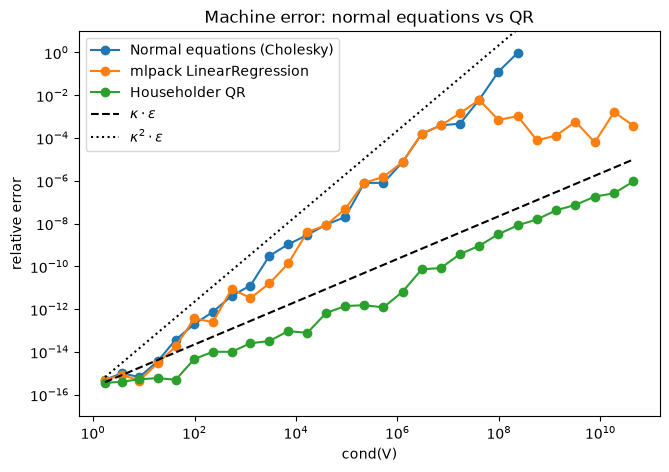

In [10]:
eps = np.finfo(float).eps
plt.figure(figsize=(7.5, 5))
for name in METHODS:
    plt.loglog(kappas, errors[name], "o-", label=name)
plt.loglog(kappas, kappas * eps, "k--", label=r"$\kappa \cdot \epsilon$")
plt.loglog(kappas, kappas**2 * eps, "k:", label=r"$\kappa^2 \cdot \epsilon$")
plt.ylim(1e-17, 10)
plt.xlabel("cond(V)")
plt.ylabel("relative error")
plt.title("Machine error: normal equations vs QR")
plt.legend()
plt.show()

### Conclusions From both graphs:

As stated previsouly mlpack focuses on scalability and efficiency, which can be seen here as just as efficient as the household QR, but it starts to lose accuracy as the condition number grows. After some further research the work around that armadillo impliments is that after a certain condion is met, specifcally where mlpack starts to veer off. This condition once met then switches to solving with a least-squares solve from LAPACK. This inturn allows mlpack to keep its intial effiecency while minimizing error after certain point when using Choleskys. This switch allows for stability as to prevent it from crashing.